In [11]:
import requests
from pathlib import Path
import pandas as pd
import numpy as np

In [3]:
#ruta onde se garda o ficheiro
destino = Path("../datos/raw/meteo_alvedro_2021_2025.csv")
URL = "https://raw.githubusercontent.com/bigdatawirtz/datasets/main/datasets/meteo_alvedro_2021_2025.csv"

#descarganse os datos unha sola vez
if not destino.exists():
    print("Descargando os datos da estación de Alvedro...")
    resposta = requests.get(URL, timeout=30)
    resposta.raise_for_status() #control de erros
    
    #escríbense os datos en bruto como bytes
    destino.write_bytes(resposta.content)
    print("Datos gardados con éxito")
else:
    print("Os datos xa estaban descargados en datos/raw/.")

Os datos xa estaban descargados en datos/raw/.


In [4]:
#lense as primeiras 15 liñas do ficheiro para ver os seus problemas
with open(destino, "rb") as ficheiro:
    for i in range(15):
        liña = ficheiro.readline()
        print(liña)

b'Servizo de exportaci\xf3n de datos meteorol\xf3xicos\n'
b'Estaci\xf3n: A Coru\xf1a / Alvedro (aeroporto) \xb7 Indicativo: 08002\n'
b'Latitude: 43,3000 \xb7 Lonxitude: -8,3833 \xb7 Altitude: 97 m\n'
b'Per\xedodo: 01/01/2021 - 31/12/2025\n'
b'Fonte orixinal: Meteostat (meteostat.net). Ficheiro modificado con fins did\xe1cticos.\n'
b'\n'
b'Data;Temp. media (\xbaC);Temp. m\xednima (\xbaC);Temp. m\xe1xima (\xbaC);Humidade relativa (%);Precipitaci\xf3n (mm);Vento medio (km/h);Presi\xf3n (hPa)\n'
b'2021-01-01;5,9;3,3;9,1;87;12,2;11,0;1.015,7\n'
b'2021-01-02;5,5;3,1;9,7;91;9,8;6,4;1.019,8\n'
b'2021-01-03;5,6;3,0;8,4;92;12,4;8,5;1.018,9\n'
b'2021-01-04;3,6;-0,3;6,8;92;4,7;7,8;1.015,4\n'
b'2021-01-05;2,8;-1,5;9,4;94;1,2;6,2;1.014,6\n'
b'2021-01-06;2,1;-2,5;8,6;90;0,3;3,3;1.015,7\n'
b'2021-01-07;2,3;-2,4;8,7;90;0,2;7,0;1.016,1\n'
b'2021-01-08;2,5;-3,2;8,8;85;1,0;7,2;1.015,7\n'


In [5]:
#ler o ficheiro aplicando todo o que se ve no paso anterior
df = pd.read_csv(
    destino, 
    encoding="latin1",   #para que lea ben os acentos e as 'ñ' (\xf3, \xf1)
    sep=";",             #o separador é o punto e coma
    skiprows=6,          #saltase as 6 liñas de metadatos iniciais
    decimal=",",         #os decimais levan coma
    thousands="."        #os miles levan punto
)

df.head()

,Data,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC),Humidade relativa (%),Precipitación (mm),Vento medio (km/h),Presión (hPa)
0,2021-01-01,5.9,3.3,9.1,87,"12,2",11.0,1015.7
1,2021-01-02,5.5,3.1,9.7,91,"9,8",6.4,1019.8
2,2021-01-03,5.6,3.0,8.4,92,"12,4",8.5,1018.9
3,2021-01-04,3.6,-0.3,6.8,92,"4,7",7.8,1015.4
4,2021-01-05,2.8,-1.5,9.4,94,"1,2",6.2,1014.6


In [6]:
#Comproba os tipos de todas as columnas e asegúrate de que a data é unha data en todas as filas.
# Se unha columna numérica se le como texto, descubre por que.
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1812 entries, 0 to 1811
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Data                   1812 non-null   str    
 1   Temp. media (ºC)       1803 non-null   float64
 2   Temp. mínima (ºC)      1806 non-null   float64
 3   Temp. máxima (ºC)      1803 non-null   float64
 4   Humidade relativa (%)  1812 non-null   int64  
 5   Precipitación (mm)     1804 non-null   str    
 6   Vento medio (km/h)     1812 non-null   float64
 7   Presión (hPa)          1811 non-null   float64
dtypes: float64(5), int64(1), str(2)
memory usage: 113.4 KB


In [7]:
# arranxar o problema de tipos de datos
# 1. convertir a columna 'Data' a tipo datetime co día primeiro (dayfirst=True) 
# e co formato mixto (format="mixed") para que poida interpretar datas con diferentes formatos
df["Data"] = pd.to_datetime(df["Data"], format="mixed", dayfirst=True)

# 2. buscar o problema en Precipitación
# pd.to_numeric tenta converter todo a números. Con errors='coerce', se atopa texto, ponlle un nulo (NaN)
precipitacion_num = pd.to_numeric(df["Precipitación (mm)"], errors="coerce")

# filtrar as filas que tiñan algo escrito pero que fallaron ao converterse a número
filas_con_erros = df[precipitacion_num.isna() & df["Precipitación (mm)"].notna()]

# mostrar cales son eses datos infiltrados
print("Valores de texto atopados na columna de Precipitación:")
print(filas_con_erros[["Data", "Precipitación (mm)"]])

Valores de texto atopados na columna de Precipitación:
           Data Precipitación (mm)
0    2021-01-01               12,2
1    2021-02-01                9,8
2    2021-03-01               12,4
3    2021-04-01                4,7
4    2021-05-01                1,2
...         ...                ...
1807 2025-10-06                 Ip
1808 2021-04-16                0,0
1809 2022-05-21                2,9
1810 2025-12-10                0,0
1811 2023-08-17                0,5

[1802 rows x 2 columns]


In [8]:
# limpiar a columna de Precipitación convertendo a columna a tipo numérico
# 1. sustituir "Ip" (Inapreciable) por "0"
df["Precipitación (mm)"] = df["Precipitación (mm)"].replace("Ip", "0")

# 2. como a columna é texto, cámbianse as comas por puntos para que Python o entenda
df["Precipitación (mm)"] = df["Precipitación (mm)"].str.replace(",", ".")

# 3. convertese toda a columna a número
df["Precipitación (mm)"] = pd.to_numeric(df["Precipitación (mm)"])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1812 entries, 0 to 1811
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Data                   1812 non-null   datetime64[us]
 1   Temp. media (ºC)       1803 non-null   float64       
 2   Temp. mínima (ºC)      1806 non-null   float64       
 3   Temp. máxima (ºC)      1803 non-null   float64       
 4   Humidade relativa (%)  1812 non-null   int64         
 5   Precipitación (mm)     1804 non-null   float64       
 6   Vento medio (km/h)     1812 non-null   float64       
 7   Presión (hPa)          1811 non-null   float64       
dtypes: datetime64[us](1), float64(6), int64(1)
memory usage: 113.4 KB


In [9]:
# encher os valores ausentes (NaN)
# 1. cóntase cantos valores faltan en cada columna
print("Valores ausentes antes de limpar:")
print(df.isna().sum())

# 2. Enchemos os ocos numéricos usando interpolación linear (fai a media entre o día anterior e o seguinte)
# Limitamos a interpolación a ocos pequenos (limit=2) por se faltan moitos días seguidos.
df = df.interpolate(method='linear', limit=2)

# 3. Comprobamos que xa non quedan ocos
print("\nValores ausentes despois da interpolación:")
print(df.isna().sum())

Valores ausentes antes de limpar:
Data                     0
Temp. media (ºC)         9
Temp. mínima (ºC)        6
Temp. máxima (ºC)        9
Humidade relativa (%)    0
Precipitación (mm)       8
Vento medio (km/h)       0
Presión (hPa)            1
dtype: int64

Valores ausentes despois da interpolación:
Data                     0
Temp. media (ºC)         0
Temp. mínima (ºC)        0
Temp. máxima (ºC)        0
Humidade relativa (%)    0
Precipitación (mm)       0
Vento medio (km/h)       0
Presión (hPa)            0
dtype: int64


In [ ]:
# 1. buscar filas completamente duplicadas ou coa mesma data
duplicados = df[df.duplicated(subset=["Data"], keep=False)]
print(f"Días duplicados atopados: {len(duplicados)}")

# 2. inconsistencias físicas: a temperatura mínima é maior que a máxima?
temp_incoherente = df[df["Temp. mínima (ºC)"] > df["Temp. máxima (ºC)"]]
print(f"\nDías con mínima maior que a máxima: {len(temp_incoherente)}")
if len(temp_incoherente) > 0:
    print(temp_incoherente[["Data", "Temp. mínima (ºC)", "Temp. media (ºC)", "Temp. máxima (ºC)"]])

# 3. valores fóra de rango: Humidade imposible (> 100% ou < 0%)
humidade_rara = df[(df["Humidade relativa (%)"] > 100) | (df["Humidade relativa (%)"] < 0)]
print(f"\nDías con humidade imposible: {len(humidade_rara)}")
if len(humidade_rara) > 0:
    print(humidade_rara[["Data", "Humidade relativa (%)"]])
    
# 4. valores fóra de rango: Temperaturas raras na Coruña (por exemplo, máis de 50ºC)
temp_rara = df[df["Temp. máxima (ºC)"] > 45]
print(f"\nDías con temperaturas extremas/falsas: {len(temp_rara)}")
if len(temp_rara) > 0:
    print(temp_rara[["Data", "Temp. máxima (ºC)"]])


Días duplicados atopados: 90

Días con mínima maior que a máxima: 3
           Data  Temp. mínima (ºC)  Temp. media (ºC)  Temp. máxima (ºC)
277  2021-07-10               11.7              16.6            -9999.0
1037 2023-11-30                6.7               9.8            -9999.0
1122 2024-02-23                5.7               8.7            -9999.0

Días con humidade imposible: 0

Días con temperaturas extremas/falsas: 0


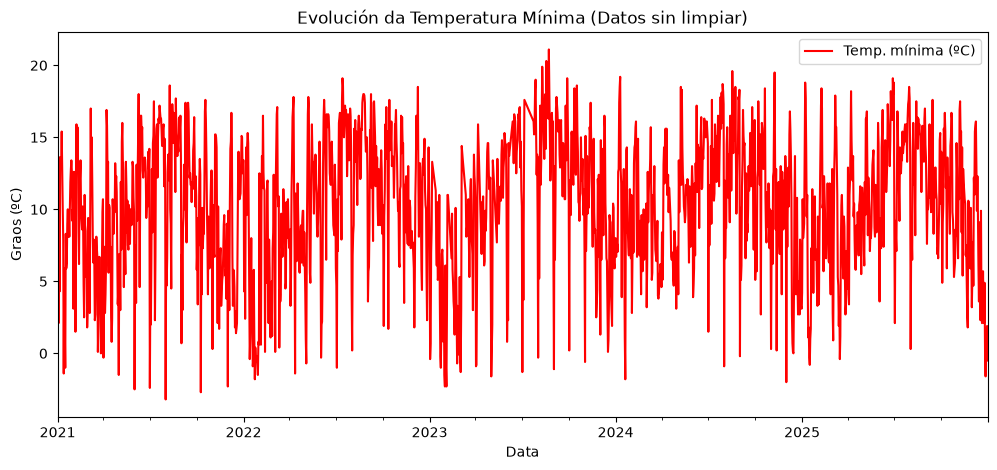

In [ ]:
import matplotlib.pyplot as plt

# gráfica da evolución da temperatura ao longo do tempo SIN LIMPIAR
df.plot(
    x="Data", 
    y="Temp. mínima (ºC)", 
    figsize=(12, 5), 
    title="Evolución da Temperatura Mínima (Datos sin limpiar)",
    color="red"
)

plt.ylabel("Graos (ºC)")
plt.xlabel("Data")
plt.show()

Filas tras borrar duplicados: 1826
Días que faltan no calendario: 0
Filas finais do dataset limpo: 1826

Datos limpos gardados con éxito en: ../datos/clean/meteo_alvedro_2021_2025_limpo.csv


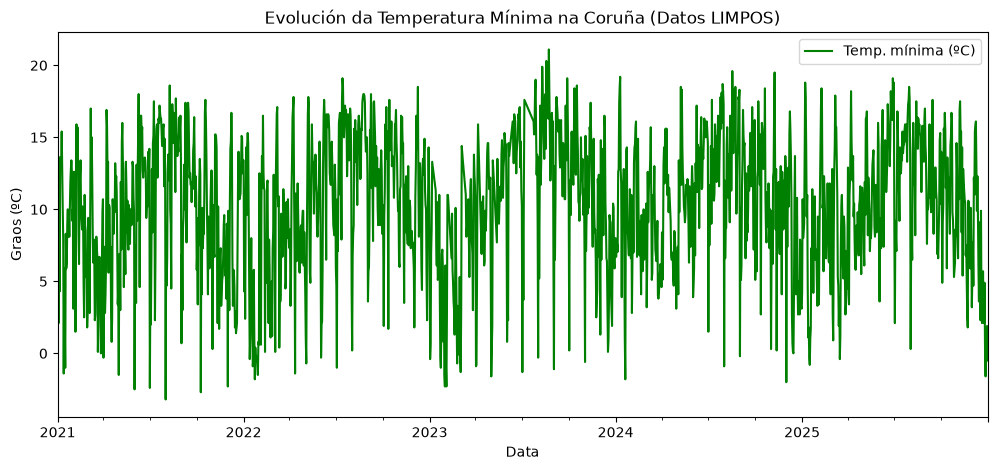

In [ ]:
# Limpieza final do dataset
# 1. elimínanse os días duplicados
df = df.drop_duplicates(subset=["Data"], keep="first")
print(f"Filas tras borrar duplicados: {len(df)}")

# 2. cámbianse os -9999.0 por nulos
df = df.replace(-9999.0, np.nan)
df = df.interpolate(method='linear')

# 3. búscanse días que faltan no calendario
# faise un calendario perfecto desde o día 1 ata o último
calendario_perfecto = pd.date_range(start=df["Data"].min(), end=df["Data"].max())
dias_que_faltan = calendario_perfecto.difference(df["Data"])

print(f"Días que faltan no calendario: {len(dias_que_faltan)}")

if len(dias_que_faltan) > 0:
    print("Engadindo as filas dos días que faltan...")
    # ponse a data como índice para poder "cadrar" o dataframe co calendario perfecto
    df = df.set_index("Data")
    df = df.reindex(calendario_perfecto)
    df = df.reset_index(names="Data") # devólvese a data a ser unha columna normal
    
    # ao crear estas novas filas, todos os seus datos estarán baleiros
    # entonces hai que interpolalos por última vez
    df = df.interpolate(method='linear')

print(f"Filas finais do dataset limpo: {len(df)}")

# 4. gárdase o resultado limpo en datos/clean/ en UTF-8 e separado por comas
ruta_clean = Path("../datos/clean/meteo_alvedro_2021_2025_limpo.csv")
ruta_clean.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(ruta_clean, index=False, encoding="utf-8", sep=",")

print(f"\nDatos limpos gardados con éxito en: {ruta_clean}")


PREGUNTA 1: Temperatura media por ano

In [14]:
# Para facelo máis fácil, creo unha columna nova que teña solo o ano
df["Ano"] = df["Data"].dt.year

# agrupo por 'Ano' e fago a media da 'Temp. media (ºC)'
temp_anual = df.groupby("Ano")["Temp. media (ºC)"].mean().round(2)

print("Temperatura media por ano na Coruña (Alvedro):")
print(temp_anual)

Temperatura media por ano na Coruña (Alvedro):
Ano
2021    14.11
2022    14.98
2023    15.07
2024    14.45
2025    14.51
Name: Temp. media (ºC), dtype: float64


Interpretación Q1: Observáse que a temperatura non ten unha tendencia liñal clara á alza neste período curto. Houbo un salto notable entre o 2021 (o ano máis frío, con 14.11 ºC) e os anos 2022-2023 (os máis cálidos, superando os 15 ºC), pero logo estabilizouse en torno aos 14.5 ºC nos dous últimos anos.